# DreamCatcher: A Predictive Analytics Framework for Sleep Disorder Screening in University Students
**ITTE105b – Analytics Application | Final Term Requirement**

Estimates the likelihood of **Insomnia** and **Sleep Apnea** from lifestyle, sleep and health indicators, to support early screening and awareness (not diagnosis).
**Data:** *BD-Uni Sleep Disorder Dataset* (Mendeley Data `9djgjvtj8d`), a real survey of university students.

**Project folder**
```
DreamCatcher_Final_Project.ipynb   this notebook
dreamcatcher_utils.py              cleaning, feature engineering and decision rules (shared with the web service)
dreamcatcher_app/                  deployment folder
  app/dataset/                     BD-Uni. Sleep Disorder Dataset.xlsx  (read by this notebook)
  app/models/                      dreamcatcher_model.joblib, label_encoder.pkl, model_card.json  (written by Section 8)
  app/static/index.html            web interface
  app/dreamcatcher_utils.py        copy of the shared module (Section 8 refreshes it)
  app/server.py                    FastAPI service
  Dockerfile, requirements.txt
```

**Contents:** 1 Data understanding & initial EDA · 2 Cleaning & features · 3 Updated EDA · 4 Split · 5 Models & tuning · 6 Evaluation · 7 Signal, feature sets & decision rules · 8 Deployment · 9 Discussion

| Professor's requirement | Section |
|---|---|
| a. Data understanding & preparation | 1–4 |
| b. Model implementation (RF, KNN, SVM) | 5 |
| c. Model evaluation | 6 |
| d. Comparative analysis & discussion | 6, 7, 9 |
| e. Model deployment | 8 |

## Clinical Background and How It Shapes This Project
| Topic | What the literature says | What it means for our model |
|---|---|---|
| **Insomnia** | DSM-5 defines it as dissatisfaction with sleep quantity or quality, at least 3 nights per week for at least 3 months, with daytime impairment, not better explained by another sleep disorder. Diagnosis rests largely on self-report, supported by questionnaires such as the ISI and PSQI. | Self-reported *sleep quality* is part of the definition, so it is a **symptom, not a cause**. Fine for screening, not for explaining causes. |
| **Insomnia in students** | A meta-analysis of 48 studies (95,938 undergraduates) found a pooled prevalence of 46.9% (95% CI 40.1-53.6); South Asian reviews report about 49-52%. | A high insomnia share is plausible. Our ~82% "any disorder" rate is a **sampling feature**, not a population rate, so predictive values (PPV/NPV) do not transfer. |
| **Sleep apnea** | Risk rises with male sex, age, obesity and hypertension. STOP-Bang (snoring, tiredness, observed apnea, blood pressure, BMI, age, neck size, gender) is the standard screening questionnaire; a score of 3+ gives about 93% sensitivity for moderate-severe OSA. | Our data has **no snoring, observed apnea, daytime tiredness or neck size**, the strongest clues, and students are young with mostly normal BMI and blood pressure, so there is little variation to learn from. |
| **Screening vs diagnosis** | Screening tools favour sensitivity: STOP-Bang 3+ reached 95% sensitivity but only 19% specificity in a high-risk clinic sample. Confirmation needs a clinical interview or sleep study. | We judge the model by **recall (sensitivity)** and report its cost (specificity, false alarms). The output is "consider a professional evaluation", **never a diagnosis**. |

**Where the data comes from:** 619 responses from students of five public universities in Bangladesh, collected with Google Forms and in-person interviews (Mendeley Data, 2026). "No Sleep Disorder" is described as *not exhibiting symptoms*, and the diagnostic method is not stated, so the labels are **symptom-based, not clinically confirmed**. This caps how well any model can do.

**Evaluation strategy that follows:** a missed real case (false negative) is worse than a false alarm, so beyond macro-F1 (used for model selection so no class is ignored) we report **per-class recall, any-disorder sensitivity/specificity and a screening threshold** (Sections 6-7).

<sub>References: Insomnia in undergraduates meta-analysis (PMC12687938) · South Asia review (PMC7888398) · DSM-5 insomnia criteria (PMC4961463) · RACGP insomnia review 2019 · STOP-Bang, Chung 2016 (PMID 26378880) · STOP-BANG vs Berlin vs OSA50 (PMC6287723) · Dataset DOI 10.17632/9djgjvtj8d.1</sub>

## 0. Setup

In [1]:
# Installs only what is missing (safe to re-run). If something is installed, restart the kernel once: Kernel > Restart.
import importlib.util, subprocess, sys
need = {"imbalanced-learn": "imblearn", "fastapi": "fastapi", "uvicorn": "uvicorn", "httpx": "httpx", "openpyxl": "openpyxl"}
missing = [pkg for pkg, mod in need.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    print("Installed:", missing, "-> please restart the kernel (Kernel > Restart) and run again.")
else:
    print("All required packages are available.")

All required packages are available.


In [2]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = str(os.cpu_count() or 1)   # silence the harmless joblib/"wmic" message on new Windows
os.environ["PYTHONWARNINGS"] = "ignore"                       # (also reaches the parallel worker processes)
import json, random, warnings
from datetime import date
from pathlib import Path

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib, sklearn
import joblib.externals.loky.backend.context as _loky_ctx
_loky_ctx.physical_cores_cache = os.cpu_count()             # skip loky's "wmic" core lookup (wmic was removed from new Windows)

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, roc_auc_score, roc_curve, auc, classification_report, ConfusionMatrixDisplay)
from sklearn.model_selection import (train_test_split, GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_validate, cross_val_predict, permutation_test_score)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, label_binarize
from sklearn.svm import SVC
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore")                  # keep the output readable (library deprecation notes only)
SEED = 42
random.seed(SEED); np.random.seed(SEED)
QUICK = os.environ.get("DC_QUICK") == "1"          # leave False for the real run
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

# --- locate the dataset and the helper module (clear message instead of a long traceback)
APP_DIR = Path("dreamcatcher_app") / "app"            # deployment folder: dataset/ and models/ live here
print("Working folder:", Path.cwd())
found = sorted(p for p in (APP_DIR / "dataset").glob("*.xlsx") if "sleep" in p.name.lower())
if not found:
    raise FileNotFoundError(f"Put the dataset (.xlsx) in this folder: {(APP_DIR / 'dataset').resolve()}")
if not Path("dreamcatcher_utils.py").exists():
    raise FileNotFoundError(f"Put dreamcatcher_utils.py in this folder: {Path.cwd()}")
DATA_PATH = found[0]
print("Dataset:", DATA_PATH.name)

import dreamcatcher_utils as U

Working folder: C:\Users\Asus\ITTE 105B_DreamCatcher
Dataset: BD-Uni. Sleep Disorder Dataset.xlsx


## 1. Data Understanding & Initial EDA
The raw survey export is inspected **before** anything is changed.

In [3]:
df_raw = pd.read_excel(DATA_PATH)
print(f"{df_raw.shape[0]} observations x {df_raw.shape[1]} columns | exact duplicate rows: {df_raw.duplicated().sum()}")
pd.DataFrame({"dtype": df_raw.dtypes.astype(str), "unique values": df_raw.nunique(), "missing": df_raw.isna().sum(),
              "example": [str(df_raw[c].iloc[0])[:40] for c in df_raw.columns]})

619 observations x 13 columns | exact duplicate rows: 0


,dtype,unique values,missing,example
Department,object,38,0,CSE
Gender,object,2,0,Female
Age,int64,11,0,23
Sleep Duration,object,6,0,8 hours or more
Quality of Sleep,object,5,0,Good
Physical Activity Level,int64,110,0,50
Stress Level,object,5,0,Moderate
BMI Category,object,4,0,Normal (BMI 18.5–24.9)
Blood Pressure (systolic/diastolic),object,329,0,120/60
Heart Rate (bpm),int64,55,0,67


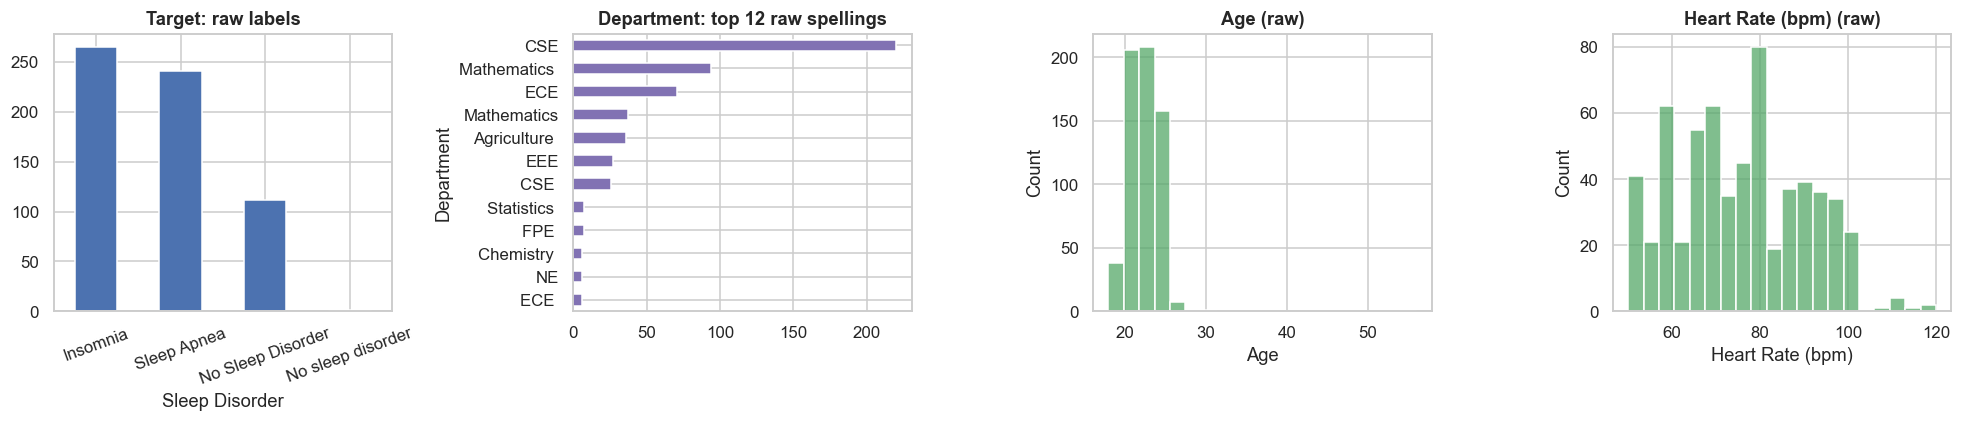

Distinct raw spellings: {'Department': 38, 'Sleep Duration': 6, 'Quality of Sleep': 5, 'Daily Steps': 6, 'Sleep Disorder': 4}
Blood-pressure strings that are not a valid 'sys/dia': 0


In [4]:
# Initial EDA on the RAW file (before any cleaning): what problems does the data have?
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
df_raw["Sleep Disorder"].astype(str).value_counts().plot(kind="bar", ax=axes[0], color="#4c72b0"); axes[0].set_title("Target: raw labels"); axes[0].tick_params(axis="x", rotation=20)
df_raw["Department"].astype(str).value_counts().head(12).plot(kind="barh", ax=axes[1], color="#8172b3"); axes[1].set_title("Department: top 12 raw spellings"); axes[1].invert_yaxis()
for ax, c in zip(axes[2:], ["Age", "Heart Rate (bpm)"]):
    sns.histplot(df_raw[c], bins=20, ax=ax, color="#55a868"); ax.set_title(f"{c} (raw)")
plt.tight_layout(); plt.show()
print("Distinct raw spellings:", {c: int(df_raw[c].nunique()) for c in ["Department", "Sleep Duration", "Quality of Sleep", "Daily Steps", "Sleep Disorder"]})
bp_col = df_raw["Blood Pressure (systolic/diastolic)"].astype(str)
print("Blood-pressure strings that are not a valid 'sys/dia':", int((~bp_col.str.match(r"^\s*\d{2,3}\s*/\s*\d{2,3}\s*$")).sum()))

The file is a **survey export**: apart from age, heart rate and activity minutes, almost every column is a *text answer*. Nothing is missing, but the text is inconsistent (case, dashes, spaces, 38 spellings of department). "No Sleep Disorder" is a real label here (in the synthetic dataset it was created from blanks).

| Type | Variables |
|---|---|
| Target (3 classes) | Insomnia · Sleep Apnea · No Sleep Disorder |
| Numerical | Age, Physical Activity (min/day), Heart Rate, Blood Pressure (string `sys/dia`) |
| Ordinal | Sleep Duration, Sleep Quality, Stress Level, BMI Category, Daily Steps (bands), Academic Level |
| Nominal | Gender, Department |

## 2. Cleaning & Feature Engineering
All cleaning is **rule-based** (nothing is learned from the data), so it is safe to apply before splitting. Statistics-based steps (imputing, scaling, encoding) happen later inside the model pipeline. The rules live in `dreamcatcher_utils.py` so the API cleans inputs identically.

In [5]:
df = df_raw.rename(columns=U.RENAME)
y_all = df["sleep_disorder"].map(U.clean_target)
X_all = U.build_features(df)
assert y_all.notna().all() and X_all[U.ORD_COLS + ["gender"]].notna().all().all(), "unmapped answer found"

print(f"Impossible blood-pressure readings set to missing: {X_all['systolic'].isna().sum()}")
print(f"Ages above 30 (capped at 30): {(df['age'] > 30).sum()}")
print(f"Activity answers that are multiples of 10: {(df['physical_activity'] % 10 == 0).mean():.0%} (rounded self-report)\n")
pd.concat([y_all.value_counts().rename("n"), (y_all.value_counts(normalize=True) * 100).round(1).rename("%")], axis=1)

Impossible blood-pressure readings set to missing: 3
Ages above 30 (capped at 30): 2
Activity answers that are multiples of 10: 36% (rounded self-report)



,n,%
sleep_disorder,,
Insomnia,265,42.8
Sleep Apnea,241,38.9
No Sleep Disorder,113,18.3


**Decisions**
- **Text normalisation** and department grouping (CSE, Mathematics, ECE, Agriculture, Other).
- **Ordinal encoding** for ordered answers keeps their order (one-hot would discard it).
- **Blood pressure** → systolic, diastolic, **MAP** and **pulse pressure**; three impossible readings (`118/26`, `80/90`, `80/120`) become missing and are imputed later.
- Class balance: **Insomnia 43% · Sleep Apnea 39% · None 18%**. *None* is the **minority** (the opposite of the synthetic data), so we optimise **macro-F1**, not accuracy.

**Preprocessing summary (what, how, and where it is applied)**
| Step | Method | Applied |
|---|---|---|
| Missing / impossible values | 3 impossible blood-pressure readings set to missing, then median (numeric) or most-frequent (ordinal) imputation | Imputation inside the pipeline, fitted on training folds only |
| Outliers | Fixed plausible ranges (age 18-30, heart rate 40-200, activity 0-180 min); no rows removed | Rule-based, before the split |
| Encoding | Ordinal answers to integer codes; gender and department one-hot; target with `LabelEncoder` | Rules in `dreamcatcher_utils.py`; one-hot in the pipeline |
| Scaling | `StandardScaler` on numeric and ordinal columns | Pipeline |
| Class imbalance | Optional `SMOTE` (tuned by the grid search) | Pipeline, training folds only |
| Feature selection | `SelectKBest` (ANOVA F-test), `k` tuned | Pipeline |
| Train/test split | Stratified 80/20, `random_state=42` | Section 4 |

## 3. Updated EDA (after cleaning)
Descriptive only: no tuning or selection uses test labels. Statistical feature ranking is done later on the training set only (Section 7).

,count,mean,std,min,25%,50%,75%,max
age,619.0,22.13,1.96,18.00,20.00,22.00,24.0,30.00
physical_activity,619.0,56.39,33.49,10.00,30.00,50.00,84.5,120.00
heart_rate,619.0,75.48,14.49,50.00,64.00,75.00,87.0,120.00
systolic,616.0,120.74,9.38,90.00,115.00,120.00,126.0,150.00
diastolic,616.0,74.63,9.19,50.00,68.00,75.00,80.0,97.00
map,616.0,90.00,8.55,66.67,83.33,90.67,95.0,112.33
pulse_pressure,616.0,46.11,7.51,2.00,40.00,47.00,51.0,70.00


,type,categories,most common,share of most common
sleep_duration,ordinal,4,8 hours or more,0.473344
sleep_quality,ordinal,5,Average,0.353796
stress_level,ordinal,5,High,0.260097
bmi_category,ordinal,4,Normal,0.34895
daily_steps,ordinal,5,"12,000-15,999",0.208401
academic_level,ordinal,4,Level-1,0.399031
gender,nominal,2,Male,0.529887
department,nominal,5,CSE,0.400646


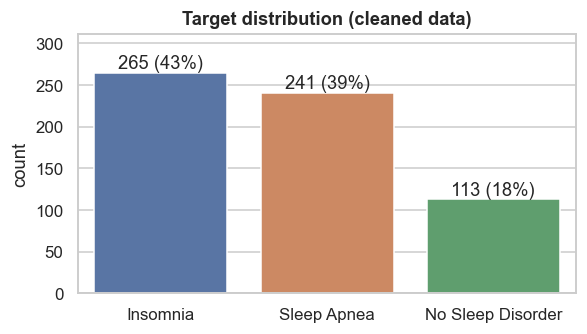

In [6]:
order = ["Insomnia", "Sleep Apnea", "No Sleep Disorder"]
colors = {"Insomnia": "#4c72b0", "Sleep Apnea": "#dd8452", "No Sleep Disorder": "#55a868"}

# 3.1 summary statistics + class distribution
display(X_all[U.NUM_COLS].describe().T.round(2))
def labelled(c):
    s_ = X_all[c]
    return s_.map(lambda i: U.OPTIONS[c][int(i) - (1 if c == "academic_level" else 0)]) if c in U.ORD_COLS else s_
cat_summary = pd.DataFrame({c: {"type": "ordinal" if c in U.ORD_COLS else "nominal", "categories": labelled(c).nunique(),
                               "most common": labelled(c).mode()[0], "share of most common": (labelled(c) == labelled(c).mode()[0]).mean()}
                           for c in U.ORD_COLS + U.CAT_COLS}).T
display(cat_summary)
fig, ax = plt.subplots(figsize=(5.5, 3.2))
sns.countplot(x=y_all, order=order, hue=y_all, palette=colors, legend=False, ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())} ({p.get_height() / len(y_all):.0%})", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set_title("Target distribution (cleaned data)"); ax.set_xlabel(""); ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
plt.tight_layout(); plt.show()

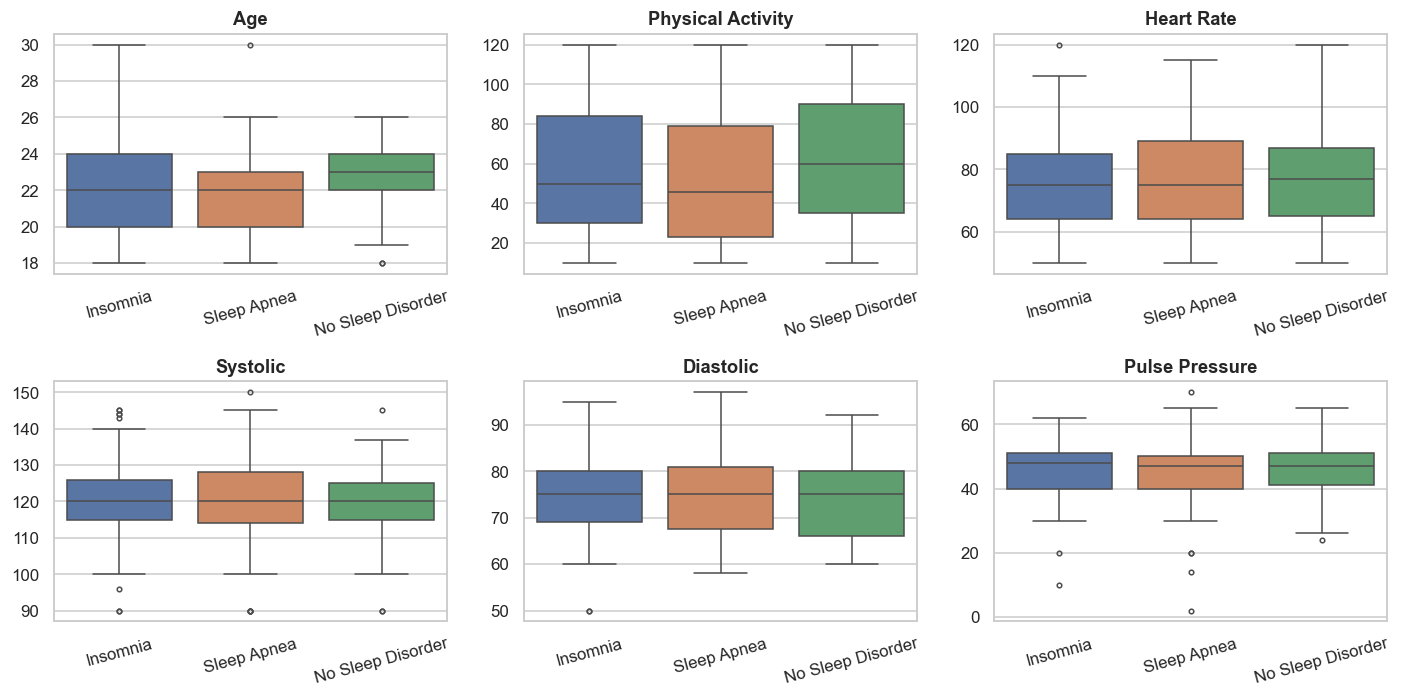

In [7]:
# 3.2 numerical features by class
num_show = ["age", "physical_activity", "heart_rate", "systolic", "diastolic", "pulse_pressure"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, c in zip(axes.ravel(), num_show):
    sns.boxplot(x=y_all, y=X_all[c], order=order, hue=y_all, palette=colors, legend=False, ax=ax, fliersize=3)
    ax.set_xlabel(""); ax.set_ylabel(""); ax.set_title(c.replace("_", " ").title()); ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

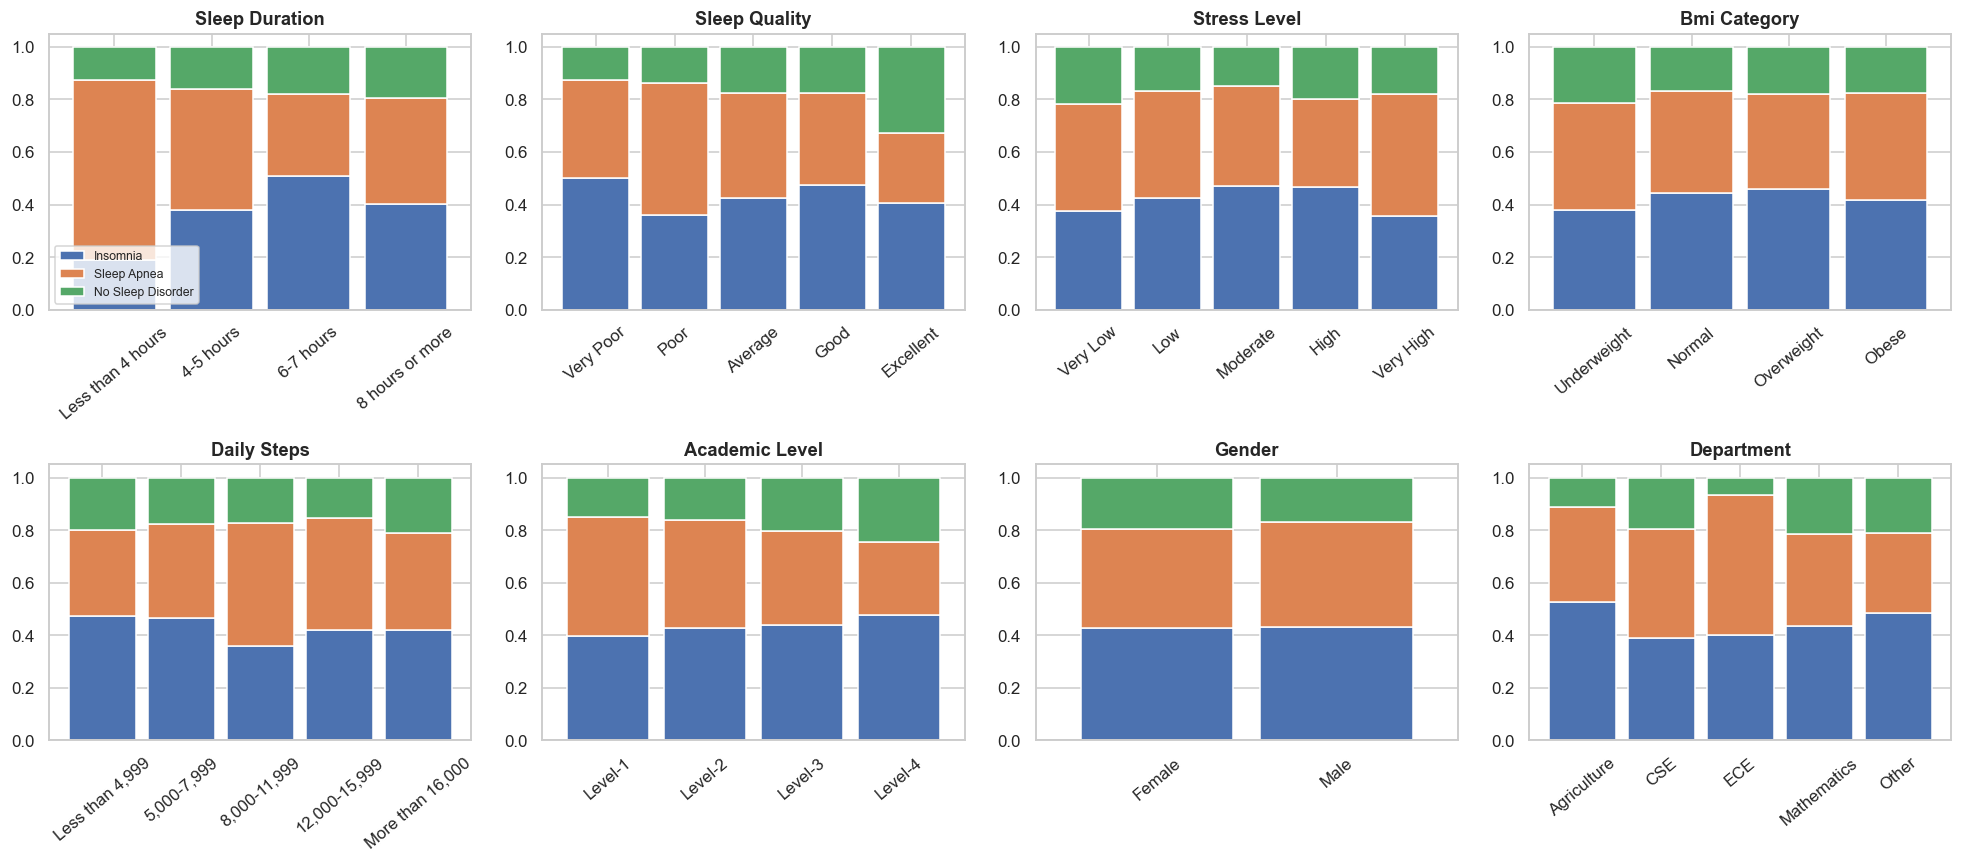

In [8]:
# 3.3 categorical / ordinal features vs class (share of each disorder within every answer)
cat_show = ["sleep_duration", "sleep_quality", "stress_level", "bmi_category", "daily_steps", "academic_level", "gender", "department"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), cat_show):
    ct = pd.crosstab(X_all[c], y_all, normalize="index")[order]
    if c in U.ORD_COLS:
        ct.index = [U.OPTIONS[c][int(i) - (1 if c == "academic_level" else 0)] for i in ct.index]
    ct.plot(kind="bar", stacked=True, ax=ax, color=[colors[k] for k in order], legend=False, width=0.85)
    ax.set_title(c.replace("_", " ").title()); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=40)
axes[0, 0].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

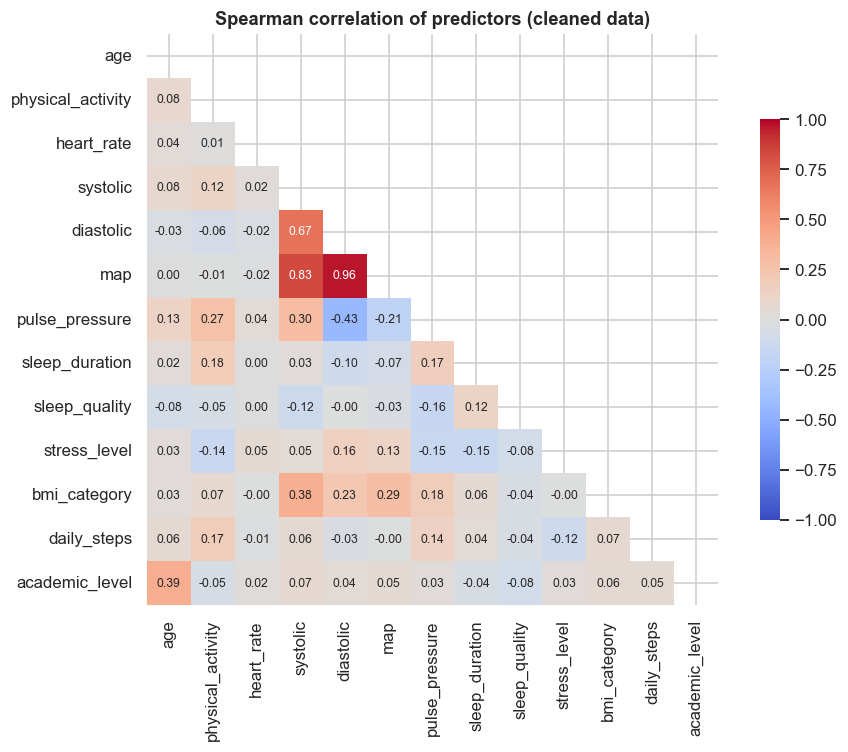

In [9]:
# 3.4 predictor correlations (Spearman)
corr = X_all[U.NUM_COLS + U.ORD_COLS].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, bool)), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": .7}, annot_kws={"size": 8}, ax=ax)
ax.set_title("Spearman correlation of predictors (cleaned data)"); plt.tight_layout(); plt.show()

**EDA takeaways**
1. Predictors look only **weakly** related to the target (formal tests in Section 7). This is typical for self-reported survey data and is the key point for the discussion.
2. Sleep quality/duration move in the expected direction but the classes overlap heavily; stress, BMI, gender and blood pressure barely separate them.
3. Systolic, diastolic and MAP are strongly inter-correlated (MAP is derived from them). Tree models tolerate this; `SelectKBest` also trims redundancy.
4. *No Sleep Disorder* is the minority class, so accuracy alone is misleading.

## 4. Train/Test Split
Stratified 80/20. The test set is **not touched** until Section 6. Models are trained on **integer-encoded labels** (`LabelEncoder`); this also avoids a string-label bug in some scikit-learn versions of KNN.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED)
split = pd.DataFrame({"Train": y_train.value_counts(), "Test": y_test.value_counts()})
split["Train %"] = (split["Train"] / len(y_train) * 100).round(1)
split["Test %"] = (split["Test"] / len(y_test) * 100).round(1)
le = LabelEncoder().fit(U.CLASSES)       # Insomnia=0, No Sleep Disorder=1, Sleep Apnea=2
y_train_enc, y_test_enc, y_all_enc = le.transform(y_train), le.transform(y_test), le.transform(y_all)
print(f"Train {X_train.shape} | Test {X_test.shape}")
split

Train (495, 15) | Test (124, 15)


,Train,Test,Train %,Test %
sleep_disorder,,,,
Insomnia,212,53,42.8,42.7
Sleep Apnea,193,48,39.0,38.7
No Sleep Disorder,90,23,18.2,18.5


## 5. Model Implementation
One **leakage-safe pipeline** per model, fitted on training folds only:
`impute → scale / one-hot → (optional SMOTE) → SelectKBest → classifier`

`GridSearchCV` with **5-fold × 2-repeat stratified CV**, optimising **macro-F1**. SMOTE on/off, number of selected features and class weights are tuned together with each model's own hyperparameters.

In [11]:
def make_pipe(clf, exclude=()):
    prep = ColumnTransformer([
        ("num", ImbPipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), [c for c in U.NUM_COLS if c not in exclude]),
        ("ord", ImbPipeline([("imp", SimpleImputer(strategy="most_frequent")), ("sc", StandardScaler())]), [c for c in U.ORD_COLS if c not in exclude]),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False), [c for c in U.CAT_COLS if c not in exclude]),
    ])
    return ImbPipeline([("prep", prep), ("smote", "passthrough"), ("select", SelectKBest(f_classif)), ("clf", clf)])

cv = RepeatedStratifiedKFold(n_splits=3 if QUICK else 5, n_repeats=1 if QUICK else 2, random_state=SEED)
scoring = {"f1_macro": "f1_macro", "balanced_accuracy": "balanced_accuracy", "accuracy": "accuracy", "recall_macro": "recall_macro"}

common = {"smote": ["passthrough", SMOTE(random_state=SEED)], "select__k": [8, 12, "all"]}
grids = {
    "Random Forest": (RandomForestClassifier(n_estimators=100 if QUICK else 300, random_state=SEED),
                      {**common, "clf__max_depth": [5, 10, None], "clf__min_samples_leaf": [2, 5], "clf__class_weight": [None, "balanced"]}),
    "KNN": (KNeighborsClassifier(),
            {**common, "clf__n_neighbors": [5, 9, 15, 25], "clf__weights": ["uniform", "distance"], "clf__p": [1, 2]}),
    "SVM": (SVC(kernel="rbf", random_state=SEED),
            {**common, "clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.01, 0.1], "clf__class_weight": [None, "balanced"]}),
}
print({n: int(np.prod([len(v) for v in g.values()])) for n, (_, g) in grids.items()}, "parameter combinations per model")
pd.DataFrame({n: {k.replace("clf__", "").replace("select__k", "k (features kept)"): [type(v).__name__ if hasattr(v, "fit_resample") else v for v in vals]
                  for k, vals in g.items()} for n, (_, g) in grids.items()}).T.fillna("-")     # the tuning grid of each model

{'Random Forest': 72, 'KNN': 96, 'SVM': 108} parameter combinations per model


,smote,k (features kept),max_depth,min_samples_leaf,class_weight,n_neighbors,weights,p,C,gamma
Random Forest,"[passthrough, SMOTE]","[8, 12, all]","[5, 10, None]","[2, 5]","[None, balanced]",-,-,-,-,-
KNN,"[passthrough, SMOTE]","[8, 12, all]",-,-,-,"[5, 9, 15, 25]","[uniform, distance]","[1, 2]",-,-
SVM,"[passthrough, SMOTE]","[8, 12, all]",-,-,"[None, balanced]",-,-,-,"[0.1, 1, 10]","[scale, 0.01, 0.1]"


In [12]:
# Grid search (the slow cell: a few minutes)
searches = {}
for name, (clf, grid) in grids.items():
    searches[name] = GridSearchCV(make_pipe(clf), grid, scoring=scoring, refit="f1_macro", cv=cv, n_jobs=-1).fit(X_train, y_train_enc)
    print(f"{name:14s} best CV macro-F1 = {searches[name].best_score_:.3f}")

# "No skill" reference, scored with the same CV
base = cross_validate(make_pipe(DummyClassifier(strategy="prior")), X_train, y_train_enc, cv=cv, scoring=scoring)
rows = [{"Model": "Baseline (majority class)", **{f"CV {k}": base[f"test_{k}"].mean() for k in scoring}, "CV f1 std": base["test_f1_macro"].std(), "Best parameters": "-"}]
for name, gs in searches.items():
    i, r = gs.best_index_, gs.cv_results_
    rows.append({"Model": name, **{f"CV {k}": r[f"mean_test_{k}"][i] for k in scoring}, "CV f1 std": r["std_test_f1_macro"][i], "Best parameters": U.pretty_params(gs.best_params_)})
cv_table = pd.DataFrame(rows).set_index("Model")
best_name = cv_table.drop(index="Baseline (majority class)")["CV f1_macro"].idxmax()     # chosen on CV only, never on the test set
print("Selected on cross-validation:", best_name)
pd.set_option("display.max_colwidth", 200)
cv_table.round(3)

Random Forest  best CV macro-F1 = 0.384
KNN            best CV macro-F1 = 0.399
SVM            best CV macro-F1 = 0.389
Selected on cross-validation: KNN


,CV f1_macro,CV balanced_accuracy,CV accuracy,CV recall_macro,CV f1 std,Best parameters
Model,,,,,,
Baseline (majority class),0.200,0.333,0.428,0.333,0.002,-
Random Forest,0.384,0.399,0.407,0.399,0.058,"{'class_weight': None, 'max_depth': 5, 'min_samples_leaf': 5, 'k': 12, 'smote': 'SMOTE'}"
KNN,0.399,0.414,0.415,0.414,0.074,"{'n_neighbors': 25, 'p': 1, 'weights': 'uniform', 'k': 'all', 'smote': 'SMOTE'}"
SVM,0.389,0.399,0.406,0.399,0.044,"{'C': 1, 'class_weight': None, 'gamma': 'scale', 'k': 12, 'smote': 'SMOTE'}"


SVM            best CV macro-F1 = 0.389


Selected on cross-validation: KNN


,CV f1_macro,CV balanced_accuracy,CV accuracy,CV recall_macro,CV f1 std,Best parameters
Model,,,,,,
Baseline (majority class),0.200,0.333,0.428,0.333,0.002,-
Random Forest,0.384,0.399,0.407,0.399,0.058,"{'class_weight': None, 'max_depth': 5, 'min_samples_leaf': 5, 'k': 12, 'smote': 'SMOTE'}"
KNN,0.399,0.414,0.415,0.414,0.074,"{'n_neighbors': 25, 'p': 1, 'weights': 'uniform', 'k': 'all', 'smote': 'SMOTE'}"
SVM,0.389,0.399,0.406,0.399,0.044,"{'C': 1, 'class_weight': None, 'gamma': 'scale', 'k': 12, 'smote': 'SMOTE'}"


In [13]:
# Class balance: what the models actually see, and whether SMOTE helped (it is only ever applied to training folds)
prep_only = make_pipe(KNeighborsClassifier()).named_steps["prep"].fit(X_train, y_train_enc)
_, y_sm = SMOTE(random_state=SEED).fit_resample(prep_only.transform(X_train), y_train_enc)
display(pd.DataFrame({"before SMOTE": pd.Series(le.inverse_transform(y_train_enc)).value_counts(),
                      "after SMOTE": pd.Series(le.inverse_transform(y_sm)).value_counts()}))
rows = {}
for name, gs in searches.items():
    r = pd.DataFrame(gs.cv_results_); r["balancing"] = r["param_smote"].map(lambda v: "SMOTE" if hasattr(v, "fit_resample") else "none")
    rows[name] = r.groupby("balancing")["mean_test_f1_macro"].max()
print("Best CV macro-F1 with vs without SMOTE (the grid search chooses; validation folds and the test set stay untouched):")
pd.DataFrame(rows).round(3)

,before SMOTE,after SMOTE
Insomnia,212,212
Sleep Apnea,193,212
No Sleep Disorder,90,212


Best CV macro-F1 with vs without SMOTE (the grid search chooses; validation folds and the test set stay untouched):


,Random Forest,KNN,SVM
balancing,,,
SMOTE,0.384,0.399,0.389
none,0.383,0.383,0.388


## 6. Model Evaluation (held-out test set)
Each tuned model is refit on the full training set (SVM with probabilities on, needed for ROC-AUC) and scored **once** on the untouched test set.

In [14]:
def fit_final(est, X, y):
    est = clone(est)
    if hasattr(est.named_steps["clf"], "probability"):
        est.set_params(clf__probability=True)
    return est.fit(X, y)

final = {n: fit_final(gs.best_estimator_, X_train, y_train_enc) for n, gs in searches.items()}
classes = list(le.classes_)
preds = {n: le.inverse_transform(m.predict(X_test)) for n, m in final.items()}
probas = {n: m.predict_proba(X_test) for n, m in final.items()}
dummy_pred = le.inverse_transform(make_pipe(DummyClassifier(strategy="prior")).fit(X_train, y_train_enc).predict(X_test))

rows = []
for name, p in {**preds, "Baseline (majority class)": dummy_pred}.items():
    lo, hi = U.bootstrap_f1_ci(y_test, p)
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, p), "Balanced Acc.": balanced_accuracy_score(y_test, p),
                 "Precision (macro)": precision_score(y_test, p, average="macro", zero_division=0),
                 "Recall (macro)": recall_score(y_test, p, average="macro", zero_division=0),
                 "F1 (macro)": f1_score(y_test, p, average="macro"), "F1 95% CI": f"[{lo:.2f}, {hi:.2f}]",
                 "MCC": matthews_corrcoef(y_test, p),
                 **{f"Recall: {c}": r for c, r in zip(classes, recall_score(y_test, p, labels=classes, average=None, zero_division=0))},
                 "ROC-AUC (OvR)": roc_auc_score(y_test, probas[name], multi_class="ovr", labels=classes) if name in probas else np.nan})
test_table = pd.DataFrame(rows).set_index("Model")
test_table.round(3)

,Accuracy,Balanced Acc.,Precision (macro),Recall (macro),F1 (macro),F1 95% CI,MCC,Recall: Insomnia,Recall: No Sleep Disorder,Recall: Sleep Apnea,ROC-AUC (OvR)
Model,,,,,,,,,,,
Random Forest,0.379,0.378,0.362,0.378,0.362,"[0.28, 0.45]",0.055,0.264,0.348,0.521,0.573
KNN,0.452,0.479,0.450,0.479,0.454,"[0.35, 0.54]",0.165,0.434,0.609,0.396,0.656
SVM,0.427,0.432,0.419,0.432,0.416,"[0.33, 0.50]",0.137,0.340,0.435,0.521,0.602
Baseline (majority class),0.427,0.333,0.142,0.333,0.200,"[0.17, 0.23]",0.000,1.000,0.000,0.000,NaN


In [15]:
for n in final:
    print(f"===== {n} =====")
    print(classification_report(y_test, preds[n], digits=3, zero_division=0))

===== Random Forest =====
                   precision    recall  f1-score   support

         Insomnia      0.378     0.264     0.311        53
No Sleep Disorder      0.235     0.348     0.281        23
      Sleep Apnea      0.472     0.521     0.495        48

         accuracy                          0.379       124
        macro avg      0.362     0.378     0.362       124
     weighted avg      0.388     0.379     0.377       124

===== KNN =====
                   precision    recall  f1-score   support

         Insomnia      0.460     0.434     0.447        53
No Sleep Disorder      0.389     0.609     0.475        23
      Sleep Apnea      0.500     0.396     0.442        48

         accuracy                          0.452       124
        macro avg      0.450     0.479     0.454       124
     weighted avg      0.462     0.452     0.450       124

===== SVM =====
                   precision    recall  f1-score   support

         Insomnia      0.450     0.340     0.387  

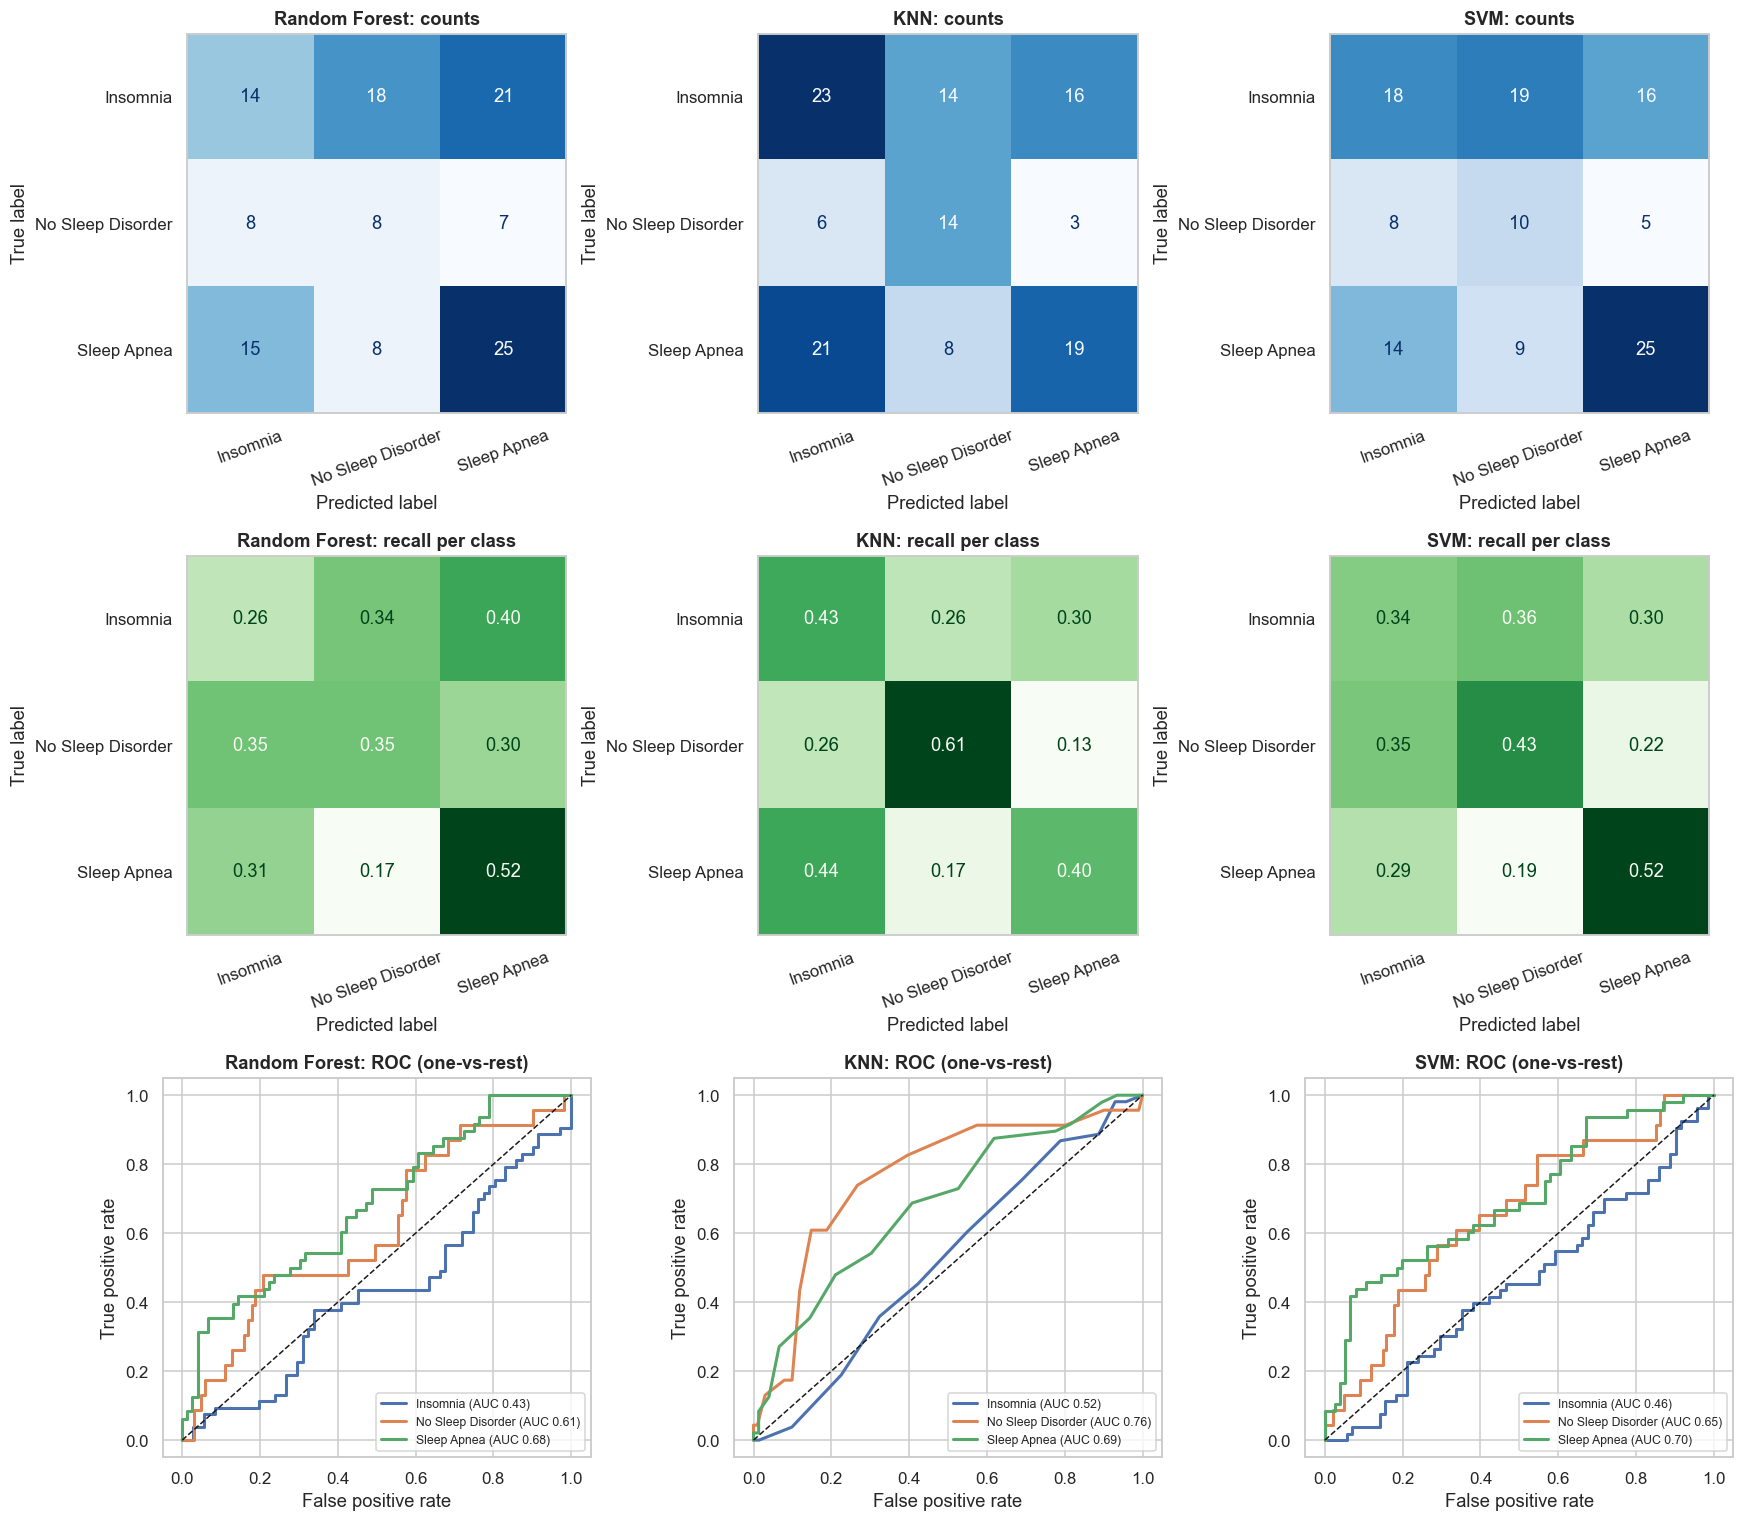

In [16]:
# Confusion matrices (counts on top, per-class recall below) and one-vs-rest ROC curves
fig, axes = plt.subplots(3, 3, figsize=(16, 14))
Y_bin = label_binarize(y_test, classes=classes)
for j, n in enumerate(final):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[n], labels=classes, ax=axes[0, j], cmap="Blues", colorbar=False, xticks_rotation=20)
    ConfusionMatrixDisplay.from_predictions(y_test, preds[n], labels=classes, normalize="true", values_format=".2f", ax=axes[1, j], cmap="Greens", colorbar=False, xticks_rotation=20)
    axes[0, j].grid(False); axes[1, j].grid(False)          # remove the seaborn grid lines drawn over the matrix
    axes[0, j].set_title(f"{n}: counts"); axes[1, j].set_title(f"{n}: recall per class")
    for k, c in enumerate(classes):
        fpr, tpr, _ = roc_curve(Y_bin[:, k], probas[n][:, k]); axes[2, j].plot(fpr, tpr, lw=2, label=f"{c} (AUC {auc(fpr, tpr):.2f})")
    axes[2, j].plot([0, 1], [0, 1], "k--", lw=1); axes[2, j].set_title(f"{n}: ROC (one-vs-rest)"); axes[2, j].legend(loc="lower right", fontsize=8)
    axes[2, j].set_xlabel("False positive rate"); axes[2, j].set_ylabel("True positive rate")
plt.tight_layout(); plt.show()

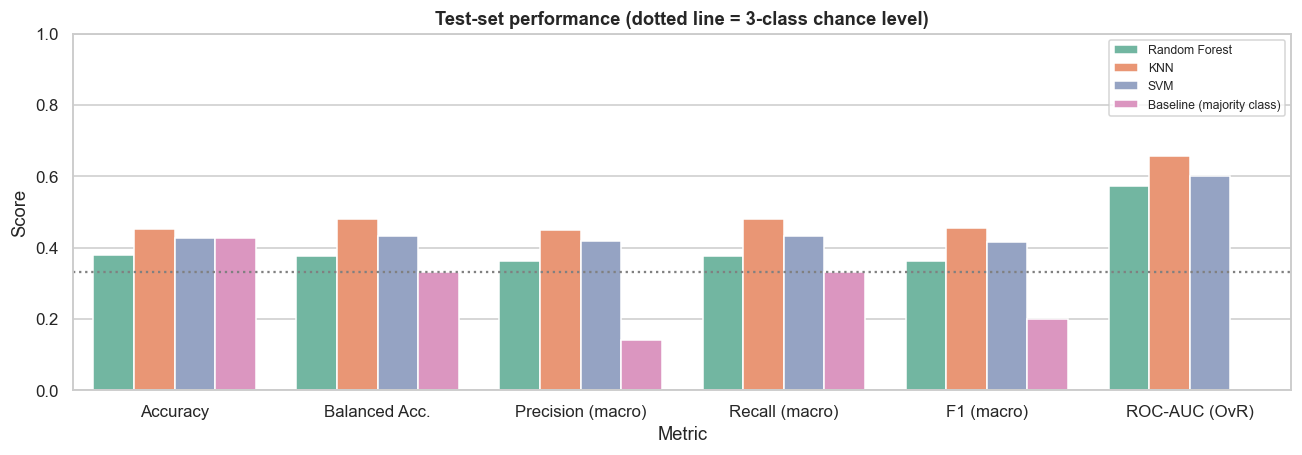

In [17]:
# Performance comparison chart
cols = ["Accuracy", "Balanced Acc.", "Precision (macro)", "Recall (macro)", "F1 (macro)", "ROC-AUC (OvR)"]
plot_df = test_table[cols].reset_index().melt("Model", var_name="Metric", value_name="Score")
fig, ax = plt.subplots(figsize=(12, 4.3))
sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model", palette="Set2", ax=ax)
ax.axhline(1 / 3, ls=":", c="gray"); ax.set_ylim(0, 1); ax.set_title("Test-set performance (dotted line = 3-class chance level)")
ax.legend(loc="upper right", fontsize=8); plt.tight_layout(); plt.show()

### 6.x Interpretation of the evaluation (numbers from the run with `random_state=42`; update them if you re-run)
- **Test set (124 students):** KNN scored best (accuracy 0.452, balanced accuracy 0.479, macro-F1 0.454, MCC 0.165), then SVM (macro-F1 0.416) and Random Forest (0.362, MCC 0.055). The majority baseline already reaches accuracy 0.427 (the same as SVM) but macro-F1 of only 0.200, which is why **accuracy alone is misleading** here.
- **Confusion matrices:** the main confusion is *between Insomnia and Sleep Apnea* (e.g. Random Forest labelled 21 of 53 insomnia cases as sleep apnea and 15 of 48 apnea cases as insomnia). KNN finds the most "No Sleep Disorder" students (14 of 23) but misses many apnea cases (recall 0.40); Random Forest and SVM find more apnea (25 of 48 each).
- **ROC curves** sit only modestly above the diagonal, in line with the small effect sizes found in the EDA.
- **SMOTE:** the best CV macro-F1 with vs without SMOTE was 0.384 vs 0.383 (RF), 0.399 vs 0.383 (KNN) and 0.389 vs 0.388 (SVM): a small gain for KNN, negligible for the others, so the class imbalance (None = 18%) is mild.
- **Confidence intervals overlap** (KNN 0.35-0.54, SVM 0.33-0.50, RF 0.28-0.45), so KNN is *slightly better*, not significantly better.

In [18]:
# Pipeline of the selected model (preprocessing -> SMOTE -> feature selection -> classifier)
from sklearn import set_config
set_config(display="diagram")
final[best_name]

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('sc',
                                                                   StandardScaler())]),
                                                  ['age', 'physical_activity',
                                                   'heart_rate', 'systolic',
                                                   'diastolic', 'map',
                                                   'pulse_pressure']),
                                                 ('ord',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('sc',
                                                                   StandardScaler())]),
                                                  ['sleep_duration',
                                                   'sleep_quality',
                                                   'stress_level',
                                                   'bmi_category',
                                                   'daily_steps',
                                                   'academic_level']),
                                                 ('cat',
                                                  OneHotEncoder(drop='if_binary',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['gender', 'department'])])),
                ('smote', SMOTE(random_state=42)),
                ('select', SelectKBest(k='all')),
                ('clf', KNeighborsClassifier(n_neighbors=25, p=1))])

## 7. Is the Signal Real, and Which Features Matter?
- **Permutation test:** shuffles the labels many times; the p-value says how often shuffled labels score as well as the real ones.
- **Permutation importance:** on the test set, how much macro-F1 drops when one feature is shuffled (works for any model, on the original feature names).

KNN: CV macro-F1 0.383 | shuffled-label mean 0.318 | permutation p-value 0.010


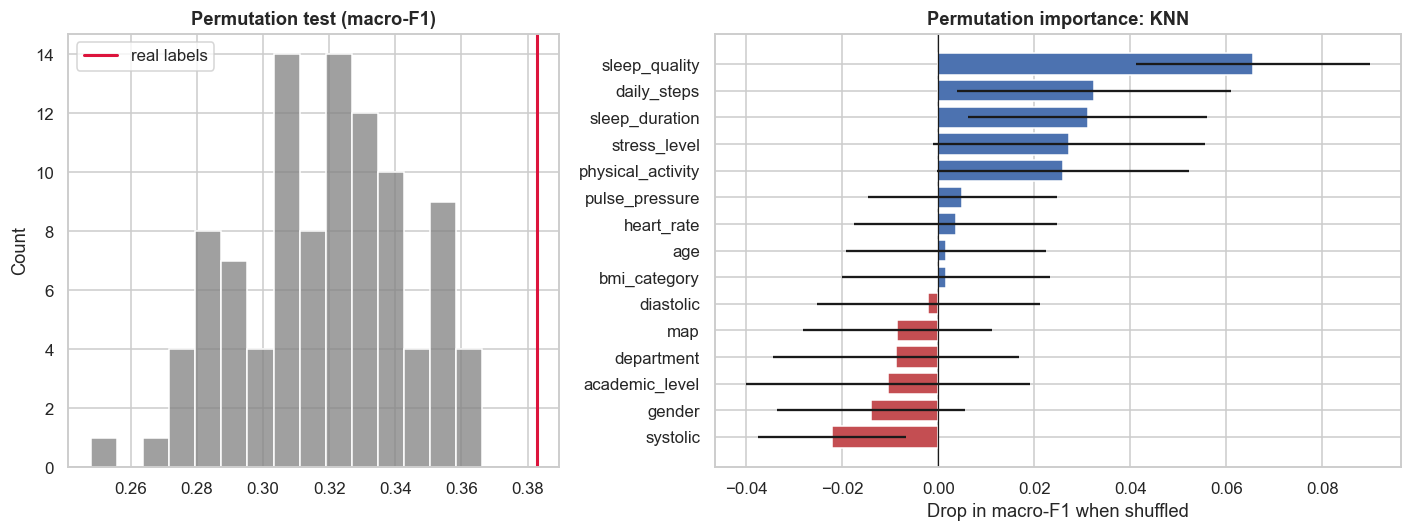

Bars near zero (or with error bars crossing zero) carry no reliable signal. The test set is small: read this as a ranking hint.


In [19]:
score, perm_scores, pval = permutation_test_score(
    clone(searches[best_name].best_estimator_), X_train, y_train_enc, scoring="f1_macro",
    cv=StratifiedKFold(5, shuffle=True, random_state=SEED), n_permutations=20 if QUICK else 100, n_jobs=-1, random_state=SEED)
print(f"{best_name}: CV macro-F1 {score:.3f} | shuffled-label mean {perm_scores.mean():.3f} | permutation p-value {pval:.3f}")

imp = permutation_importance(final[best_name], X_test, y_test_enc, scoring="f1_macro", n_repeats=10 if QUICK else 30, random_state=SEED, n_jobs=-1)
imp_df = pd.DataFrame({"feature": X_test.columns, "mean": imp.importances_mean, "std": imp.importances_std}).sort_values("mean")

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.4]})
sns.histplot(perm_scores, bins=15, color="gray", ax=axes[0]); axes[0].axvline(score, c="crimson", lw=2, label="real labels")
axes[0].set_title("Permutation test (macro-F1)"); axes[0].legend()
axes[1].barh(imp_df["feature"], imp_df["mean"], xerr=imp_df["std"], color=np.where(imp_df["mean"] > 0, "#4c72b0", "#c44e52"))
axes[1].axvline(0, c="k", lw=.8); axes[1].set_title(f"Permutation importance: {best_name}"); axes[1].set_xlabel("Drop in macro-F1 when shuffled")
plt.tight_layout(); plt.show()
print("Bars near zero (or with error bars crossing zero) carry no reliable signal. The test set is small: read this as a ranking hint.")

### 7.2 Which features matter most, and how few are enough?
Following the professor's suggestion from the previous project: (1) rank every feature with **three independent methods** on the training data, then (2) re-run cross-validation keeping only the **top-k** features. SelectKBest sits inside the pipeline, so the ranking is redone inside each CV fold (no leakage).

,feature,consensus rank,ANOVA F,Mutual information,RF importance
0,age,3.000,16.524,0.004,0.090
1,sleep_quality,5.000,2.663,0.051,0.052
2,academic_level,5.333,5.293,0.045,0.043
3,diastolic,6.667,0.602,0.013,0.079
4,physical_activity,7.000,1.852,0.000,0.107
5,daily_steps,7.333,0.570,0.049,0.054
6,heart_rate,7.667,0.687,0.000,0.115
7,sleep_duration,9.000,0.679,0.002,0.041
8,systolic,9.667,0.127,0.001,0.082
9,department_CSE,10.000,1.051,0.001,0.018


Significance of the original features (training data, FDR-adjusted):


,feature,test,effect size,p,p (FDR-adjusted),significant (5%)
0,age,Kruskal-Wallis,0.0679,0.0000,0.0000,True
1,sleep_duration,Chi-square,0.1352,0.0060,0.0450,True
2,academic_level,Chi-square,0.1108,0.0588,0.2224,False
3,sleep_quality,Chi-square,0.1231,0.0593,0.2224,False
4,physical_activity,Kruskal-Wallis,0.0057,0.0908,0.2725,False
5,department,Chi-square,0.1096,0.1562,0.3905,False
6,daily_steps,Chi-square,0.0986,0.2923,0.6264,False
7,heart_rate,Kruskal-Wallis,-0.0015,0.5306,0.8437,False
8,diastolic,Kruskal-Wallis,-0.0023,0.6424,0.8437,False
9,bmi_category,Chi-square,0.0654,0.6446,0.8437,False


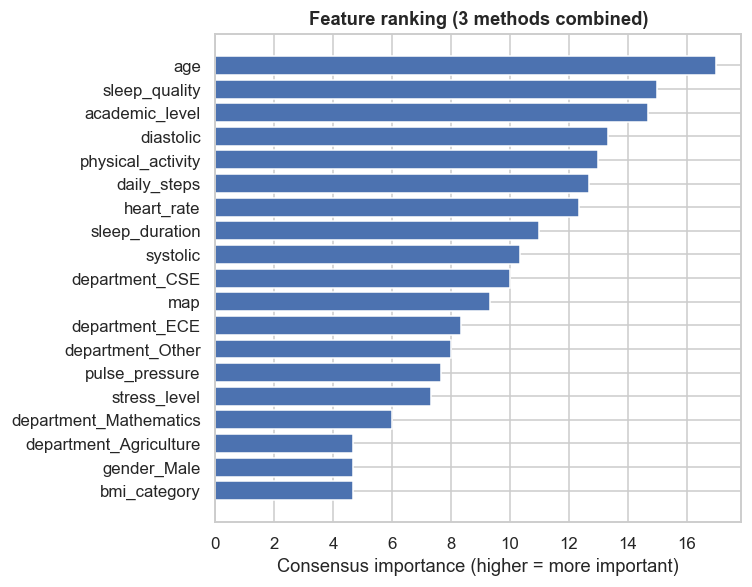

In [20]:
prep_r = make_pipe(KNeighborsClassifier()).named_steps["prep"].fit(X_train, y_train_enc)
Xp = prep_r.transform(X_train); feat_names = [n.split("__", 1)[1] for n in prep_r.get_feature_names_out()]
rank = pd.DataFrame({"feature": feat_names, "ANOVA F": f_classif(Xp, y_train_enc)[0],
                     "Mutual information": mutual_info_classif(Xp, y_train_enc, random_state=SEED),
                     "RF importance": RandomForestClassifier(500, min_samples_leaf=3, random_state=SEED).fit(Xp, y_train_enc).feature_importances_})
methods = ["ANOVA F", "Mutual information", "RF importance"]
for m in methods:
    rank[m + " rank"] = rank[m].rank(ascending=False)
rank["consensus rank"] = rank[[m + " rank" for m in methods]].mean(axis=1)
rank = rank.sort_values("consensus rank").reset_index(drop=True)
display(rank[["feature", "consensus rank"] + methods].round(3))
print("Significance of the original features (training data, FDR-adjusted):")
display(U.association_table(X_train, y_train).round(4))

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(rank["feature"][::-1], (len(rank) + 1 - rank["consensus rank"])[::-1], color="#4c72b0")
ax.set_xlabel("Consensus importance (higher = more important)"); ax.set_title("Feature ranking (3 methods combined)")
plt.tight_layout(); plt.show()

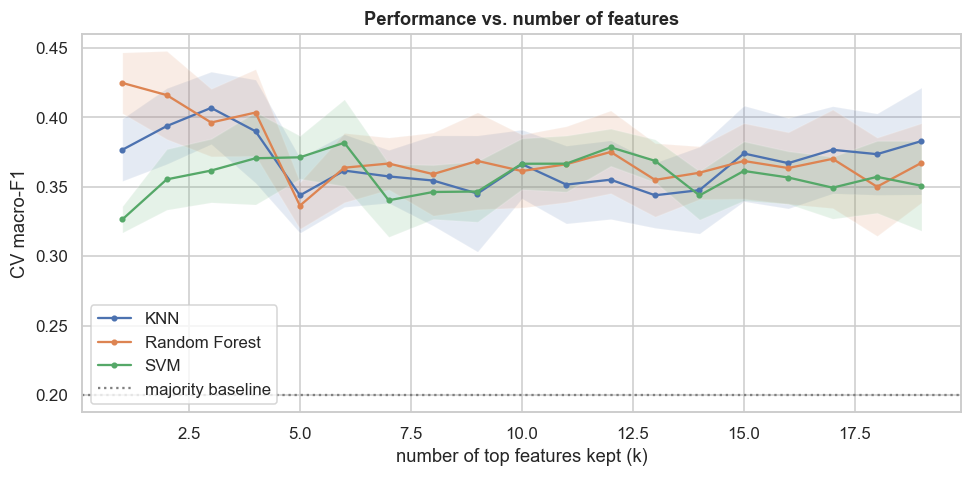

,best k,F1 at best k,smallest k within 1 SE,F1 at that k
Model,,,,
KNN,3,0.407,2,0.394
Random Forest,1,0.425,1,0.425
SVM,6,0.382,2,0.355


Top 2 features for KNN: ['age', 'academic_level']


,All features,Top 2 only
Accuracy,0.452,0.435
Balanced Acc.,0.479,0.357
F1 (macro),0.454,0.324


In [21]:
cv_k = RepeatedStratifiedKFold(n_splits=5, n_repeats=1, random_state=SEED)
ks = list(range(1, len(feat_names) + 1, 3 if QUICK else 1))
rows = []
for name, gs in searches.items():
    for k in ks:
        sc = cross_validate(clone(gs.best_estimator_).set_params(select__k=k), X_train, y_train_enc, cv=cv_k, scoring="f1_macro", n_jobs=-1)["test_score"]
        rows.append({"Model": name, "k": k, "f1": sc.mean(), "se": sc.std() / np.sqrt(len(sc))})
kc = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 4.5))
for name, g in kc.groupby("Model"):
    ax.plot(g["k"], g["f1"], marker="o", ms=3, label=name); ax.fill_between(g["k"], g["f1"] - g["se"], g["f1"] + g["se"], alpha=.15)
ax.axhline(cv_table.loc["Baseline (majority class)", "CV f1_macro"], ls=":", c="gray", label="majority baseline")
ax.set_xlabel("number of top features kept (k)"); ax.set_ylabel("CV macro-F1"); ax.set_title("Performance vs. number of features"); ax.legend()
plt.tight_layout(); plt.show()

summ = []
for name, g in kc.groupby("Model"):
    top = g.loc[g["f1"].idxmax()]; ok = g[g["f1"] >= top["f1"] - top["se"]].iloc[0]       # one-standard-error rule
    summ.append({"Model": name, "best k": int(top["k"]), "F1 at best k": top["f1"], "smallest k within 1 SE": int(ok["k"]), "F1 at that k": ok["f1"]})
summ = pd.DataFrame(summ).set_index("Model")
display(summ.round(3))

# Reduced model vs full model on the held-out test set
k_min = int(summ.loc[best_name, "smallest k within 1 SE"])
selector = SelectKBest(f_classif, k=k_min).fit(Xp, y_train_enc)
print(f"Top {k_min} features for {best_name}:", [f for f, keep in zip(feat_names, selector.get_support()) if keep])
reduced = fit_final(clone(searches[best_name].best_estimator_).set_params(select__k=k_min), X_train, y_train_enc)
pd.DataFrame({n: {"Accuracy": accuracy_score(y_test_enc, m.predict(X_test)), "Balanced Acc.": balanced_accuracy_score(y_test_enc, m.predict(X_test)),
                  "F1 (macro)": f1_score(y_test_enc, m.predict(X_test), average="macro")}
              for n, m in {"All features": final[best_name], f"Top {k_min} only": reduced}.items()}).round(3)

### 7.3 Clinically grounded feature sets
Age and academic level rank high statistically, but neither is a plausible *clinical* driver (students span a narrow age range, and academic level is a sampling artefact). We therefore compare three feature sets with the tuned hyperparameters of each model:
1. **All features**
2. **Clinically grounded**: drop academic level and department (administrative, not physiological)
3. **Clinical, no demographics**: also drop age and gender (sleep, lifestyle and vital signs only)

*Rule:* deploy the clinically grounded set unless it is clearly worse (more than one standard error below) than all features.

In [22]:
FEATURE_SETS = {
    "All features": (),
    "Clinically grounded": ("academic_level", "department"),
    "Clinical, no demographics": ("academic_level", "department", "age", "gender"),
}

def with_features(est, exclude):
    """Same tuned classifier / SMOTE choice, but only the allowed columns (all selected: isolates the effect of the feature set)."""
    sm = est.named_steps["smote"]
    return make_pipe(clone(est.named_steps["clf"]), exclude).set_params(smote=sm if isinstance(sm, str) else clone(sm), select__k="all")

rows = []
for set_name, excl in FEATURE_SETS.items():
    for name, gs in searches.items():
        r = cross_validate(with_features(gs.best_estimator_, excl), X_train, y_train_enc, cv=cv, scoring=scoring, n_jobs=-1)
        f = r["test_f1_macro"]
        rows.append({"Feature set": set_name, "Model": name, "CV macro-F1": f.mean(), "se": f.std() / np.sqrt(len(f)), "CV balanced acc.": r["test_balanced_accuracy"].mean()})
fs = pd.DataFrame(rows)
display(fs.pivot(index="Model", columns="Feature set", values="CV macro-F1")[list(FEATURE_SETS)].round(3))

b = fs[fs["Model"] == best_name].set_index("Feature set")
names_fs = list(FEATURE_SETS)
chosen_set = names_fs[1] if b.loc[names_fs[1], "CV macro-F1"] >= b.loc[names_fs[0], "CV macro-F1"] - b.loc[names_fs[0], "se"] else names_fs[0]
DEPLOY_EXCLUDE = FEATURE_SETS[chosen_set]
print(f"Selected feature set for {best_name}: {chosen_set}  (dropped: {list(DEPLOY_EXCLUDE) or 'nothing'})")

test_rows = {}
for set_name, excl in FEATURE_SETS.items():
    m = fit_final(with_features(searches[best_name].best_estimator_, excl), X_train, y_train_enc); p = m.predict(X_test)
    test_rows[set_name] = {"Accuracy": accuracy_score(y_test_enc, p), "Balanced Acc.": balanced_accuracy_score(y_test_enc, p), "F1 (macro)": f1_score(y_test_enc, p, average="macro")}
print("Held-out test set, same model:")
pd.DataFrame(test_rows).round(3)

Feature set,All features,Clinically grounded,"Clinical, no demographics"
Model,,,
KNN,0.399,0.383,0.345
Random Forest,0.382,0.385,0.343
SVM,0.365,0.381,0.341


Selected feature set for KNN: Clinically grounded  (dropped: ['academic_level', 'department'])
Held-out test set, same model:


,All features,Clinically grounded,"Clinical, no demographics"
Accuracy,0.452,0.476,0.476
Balanced Acc.,0.479,0.477,0.498
F1 (macro),0.454,0.466,0.469


,All features,Clinically grounded,"Clinical, no demographics"
Accuracy,0.452,0.476,0.476
Balanced Acc.,0.479,0.477,0.498
F1 (macro),0.454,0.466,0.469


### 7.4 Decision rules: ties and a clinical consistency check
The model returns three probabilities and the web page reports the class with the highest one. Two rules make that choice sensible for a screening aid. Both live in `dreamcatcher_utils.py`, so the notebook and the API apply exactly the same logic.

1. **Ties.** KNN with k = 25 neighbours gives probabilities in steps of 4%, so two classes can share the top score. `argmax` silently picks the alphabetically first class, so a tie between *No Sleep Disorder* and *Sleep Apnea* was reported as *No Sleep Disorder*. Because missing a real case is the worse error, a tie now goes to a disorder; between the two disorders it goes to Insomnia, the more common class in the training data.
2. **Clinical consistency.** DSM-5 insomnia requires dissatisfaction with sleep quantity or quality (see Clinical Background). A student who sleeps **8 hours or more** and rates quality **Good or Excellent** reports neither, so Insomnia is ruled out for them: P(Insomnia) is set to 0 and the other two probabilities are rescaled to sum to 1 (the model's estimate *given that it is not insomnia*).

The table shows what each rule does on the untouched test set.

In [23]:
# 7.4 From probabilities to one reported class (the rules are in dreamcatcher_utils.py and reused by the API)
deploy_est = searches[best_name].best_estimator_ if not DEPLOY_EXCLUDE else with_features(searches[best_name].best_estimator_, DEPLOY_EXCLUDE)
m_dep = fit_final(deploy_est, X_train, y_train_enc)                    # deployed configuration, trained on the training set only
P_raw = m_dep.predict_proba(X_test)
P_rule, rule_mask = U.apply_clinical_rule(P_raw, X_test, classes)
top2 = np.sort(P_raw, axis=1)[:, -2:]
print(f"Test students whose top probability is tied between two classes: {int(np.isclose(top2[:, 0], top2[:, 1]).sum())} of {len(X_test)}")
print(f"Test students with 8+ hours AND good/excellent sleep quality (clinical rule applies): {int(rule_mask.sum())}")

def class_scores(pred):
    p = le.inverse_transform(pred)
    return {"Accuracy": accuracy_score(y_test, p), "Balanced Acc.": balanced_accuracy_score(y_test, p), "F1 (macro)": f1_score(y_test, p, average="macro"),
            **{f"Recall: {c}": r for c, r in zip(classes, recall_score(y_test, p, labels=classes, average=None, zero_division=0))}}
display(pd.DataFrame({"Highest probability (first class wins a tie)": class_scores(P_raw.argmax(axis=1)),
                      "+ tie rule": class_scores(U.decide(P_raw, classes)),
                      "+ tie rule + clinical rule (deployed)": class_scores(U.decide(P_rule, classes))}).T.round(3))

# What do the survey labels say about the students the clinical rule covers? (all 619 students, descriptive only)
rule_all = U.clinical_rule_mask(X_all)
print(f"Survey labels of the {int(rule_all.sum())} students who sleep 8+ hours with good/excellent quality:")
lab = y_all[rule_all].value_counts().to_frame("n"); lab["%"] = (lab["n"] / lab["n"].sum() * 100).round(1)
lab

Test students whose top probability is tied between two classes: 5 of 124
Test students with 8+ hours AND good/excellent sleep quality (clinical rule applies): 31


,Accuracy,Balanced Acc.,F1 (macro),Recall: Insomnia,Recall: No Sleep Disorder,Recall: Sleep Apnea
Highest probability (first class wins a tie),0.476,0.477,0.466,0.453,0.478,0.500
+ tie rule,0.484,0.484,0.474,0.453,0.478,0.521
+ tie rule + clinical rule (deployed),0.444,0.461,0.438,0.340,0.522,0.521


Survey labels of the 119 students who sleep 8+ hours with good/excellent quality:


,n,%
sleep_disorder,,
Insomnia,49,41.2
Sleep Apnea,42,35.3
No Sleep Disorder,28,23.5


**Interpretation (numbers from the run with `random_state=42`).** Five of the 124 test students have a tie at the top. The tie rule slightly improves every summary score (macro-F1 0.466 → 0.474, Sleep Apnea recall 0.50 → 0.52), mainly because ties between *No Sleep Disorder* and *Sleep Apnea* now go to apnea. The clinical rule moves the other way: test macro-F1 falls to 0.438 and insomnia recall from 0.45 to 0.34, while *No Sleep Disorder* recall rises from 0.48 to 0.52. The reason is visible in the table above: in this survey 41% of the students who sleep 8+ hours with good or excellent quality are still *labelled* Insomnia. Those labels contradict the clinical definition, which fits the earlier finding that the labels are symptom-based and not clinically confirmed. We keep the rule in the deployed service because a screening aid should not tell a well-rested, satisfied sleeper that they have insomnia, and we report its cost openly. The screening thresholds below are chosen on probabilities **after** the rule, so they match what the service actually uses.

**Screening view: any disorder vs none.** DreamCatcher's purpose is screening, so we also ask "should this student be referred?". Hyperparameters are reused from Section 5. About 82% of respondents report a disorder, so a model that says "disorder" for everyone already has high precision and perfect recall; **ROC-AUC and balanced accuracy are the honest numbers.**

In [24]:
y_bin = (y_all != "No Sleep Disorder").astype(int)
cv_bin = RepeatedStratifiedKFold(n_splits=5, n_repeats=1 if QUICK else 3, random_state=SEED)
sc_bin = {"roc_auc": "roc_auc", "balanced_accuracy": "balanced_accuracy", "recall": "recall", "precision": "precision"}
models_bin = {**{n: clone(gs.best_estimator_) for n, gs in searches.items()}, "Baseline (always 'disorder')": make_pipe(DummyClassifier(strategy="prior"))}
rows = []
for name, est in models_bin.items():
    r = cross_validate(est, X_all, y_bin, cv=cv_bin, scoring=sc_bin, n_jobs=-1)
    rows.append({"Model": name, **{k: r[f"test_{k}"].mean() for k in sc_bin}})
pd.DataFrame(rows).set_index("Model").round(3)

,roc_auc,balanced_accuracy,recall,precision
Model,,,,
Random Forest,0.609,0.561,0.810,0.840
KNN,0.603,0.573,0.598,0.856
SVM,0.589,0.559,0.737,0.842
Baseline (always 'disorder'),0.500,0.500,1.000,0.817


**Choosing a screening threshold (recall first).** The model gives P(any disorder) = 1 - P(No Sleep Disorder). The clinical rule of Section 7.4 is applied first, exactly as in the API. We pick thresholds on *out-of-fold training predictions only*, then test once: **balanced** (Youden's J) and **high-sensitivity** (catch at least 90% of true cases). As with STOP-Bang, higher sensitivity costs specificity (more false alarms); which point to use is a policy decision, so both are reported.

,sensitivity (recall),specificity,precision (PPV),missed cases (FN),false alarms (FP)
Default (reported class),0.752,0.522,0.874,25.0,11.0
Balanced (threshold 0.69),0.515,0.826,0.929,49.0,4.0
High sensitivity (threshold 0.44),0.861,0.217,0.829,14.0,18.0


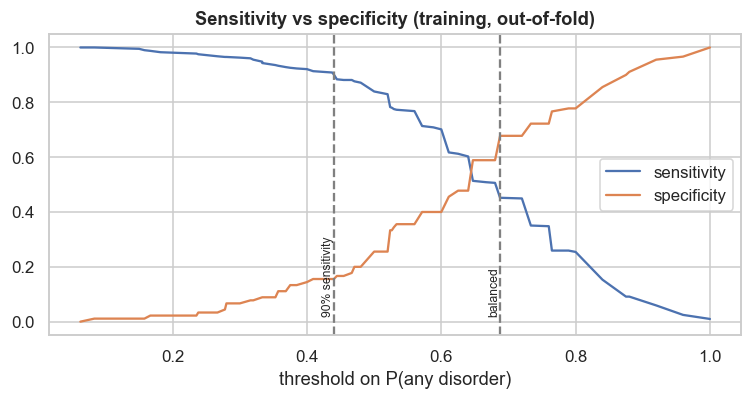

In [25]:
no_idx = classes.index("No Sleep Disorder")
est_cv = clone(deploy_est)
if hasattr(est_cv.named_steps["clf"], "probability"):
    est_cv.set_params(clf__probability=True)
oof = cross_val_predict(est_cv, X_train, y_train_enc, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba", n_jobs=-1)
oof, _ = U.apply_clinical_rule(oof, X_train, classes)                  # same rule as the deployed service
has_tr = (y_train != "No Sleep Disorder").to_numpy(); p_tr = 1 - oof[:, no_idx]
fpr, tpr, thr = roc_curve(has_tr, p_tr)
t_youden = float(thr[np.argmax(tpr - fpr)])
t_sens90 = float(thr[np.where(tpr >= 0.90)[0][0]])

p_te = 1 - P_rule[:, no_idx]; has_te = (y_test != "No Sleep Disorder").to_numpy()      # P_rule: test probabilities after the rule (Section 7.4)
def op_point(pred):
    tp, fn = int((pred & has_te).sum()), int((~pred & has_te).sum()); tn, fp = int((~pred & ~has_te).sum()), int((pred & ~has_te).sum())
    return {"sensitivity (recall)": tp / (tp + fn), "specificity": tn / (tn + fp), "precision (PPV)": tp / max(tp + fp, 1), "missed cases (FN)": fn, "false alarms (FP)": fp}
ops = pd.DataFrame({"Default (reported class)": op_point(U.decide(P_rule, classes) != no_idx),
                    f"Balanced (threshold {t_youden:.2f})": op_point(p_te >= t_youden),
                    f"High sensitivity (threshold {t_sens90:.2f})": op_point(p_te >= t_sens90)}).T
display(ops.round(3))

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(thr[1:], tpr[1:], label="sensitivity"); ax.plot(thr[1:], 1 - fpr[1:], label="specificity")
for t, lab in [(t_youden, "balanced"), (t_sens90, "90% sensitivity")]:
    ax.axvline(t, ls="--", c="gray"); ax.text(t, 0.02, lab, rotation=90, va="bottom", ha="right", fontsize=8)
ax.set_xlabel("threshold on P(any disorder)"); ax.set_title("Sensitivity vs specificity (training, out-of-fold)"); ax.legend()
plt.tight_layout(); plt.show()

## 8. Model Deployment
**Process:** best model by **cross-validated** macro-F1 → refit on **all** labelled data with its tuned hyperparameters → saved with `joblib` plus a *model card* directly into the deployment folder `dreamcatcher_app/app/models/` → served with **FastAPI** (`app/server.py`), which reuses `build_features` and the decision rules from `dreamcatcher_utils.py`, so inputs are cleaned and decided exactly like in this notebook.

```
dreamcatcher_app/
  app/
    dataset/                 BD-Uni. Sleep Disorder Dataset.xlsx
    models/                  dreamcatcher_model.joblib, label_encoder.pkl, model_card.json
    static/index.html        web interface
    __init__.py              marks app/ as a Python package
    dreamcatcher_utils.py    cleaning, feature engineering and decision rules
    server.py                FastAPI service
  Dockerfile
  requirements.txt
```

In [26]:
MODEL_DIR = APP_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
deploy_model = fit_final(deploy_est, X_all, y_all_enc)          # chosen feature set, tuned hyperparameters, all labelled data
joblib.dump(deploy_model, MODEL_DIR / "dreamcatcher_model.joblib")
joblib.dump(le, MODEL_DIR / "label_encoder.pkl")                # integer codes -> class names

def rounded(d):
    return {k: round(float(v), 4) for k, v in d.items()}
summary = ["Accuracy", "Balanced Acc.", "F1 (macro)"]
model_card = {
    "project": "DreamCatcher", "model": best_name, "trained_on": date.today().isoformat(), "n_training_rows": int(len(X_all)),
    "classes": classes, "features": U.FEATURES, "options": U.OPTIONS,
    "feature_set": chosen_set, "dropped_features": list(DEPLOY_EXCLUDE),
    "decision_rules": {"tie_order": U.TIE_ORDER,
                       "clinical_rule": "Insomnia ruled out when sleep_duration is '8 hours or more' and sleep_quality is 'Good' or 'Excellent'; the other probabilities are rescaled"},
    "screening_thresholds": {"balanced_youden": round(t_youden, 4), "high_sensitivity_90": round(t_sens90, 4)},
    "best_params": {k: str(v) for k, v in U.pretty_params(searches[best_name].best_params_).items()},
    "cv_macro_f1": round(float(cv_table.loc[best_name, "CV f1_macro"]), 4),
    "holdout_test": rounded({k: class_scores(U.decide(P_rule, classes))[k] for k in summary}),            # what the service reports
    "holdout_test_model_only": rounded({k: class_scores(P_raw.argmax(axis=1))[k] for k in summary}),   # before the decision rules
    "sklearn_version": sklearn.__version__,
    "disclaimer": "Educational screening aid built from a self-reported student survey. Not a medical diagnosis; consult a health professional.",
}
(MODEL_DIR / "model_card.json").write_text(json.dumps(model_card, indent=2), encoding="utf-8")

# the web service imports its own copy of the shared module: keep it identical to the one used here
import shutil
shutil.copy("dreamcatcher_utils.py", APP_DIR / "dreamcatcher_utils.py")
print("Saved to", MODEL_DIR, ":", sorted(p.name for p in MODEL_DIR.iterdir()))
print("Refreshed", APP_DIR / "dreamcatcher_utils.py")

Saved to dreamcatcher_app\app\models : ['dreamcatcher_model.joblib', 'label_encoder.pkl', 'model_card.json']
Refreshed dreamcatcher_app\app\dreamcatcher_utils.py


In [27]:
# The API source (dreamcatcher_app/app/server.py), shown for the report
print((APP_DIR / "server.py").read_text(encoding="utf-8"))

"""DreamCatcher web service.

Run locally (inside dreamcatcher_app):   python -m uvicorn app.server:app --reload --port 8000
Run with Docker:                         docker build -t dreamcatcher_img .   then   docker run --name dreamcatcher -p 8000:8000 dreamcatcher_img
Pages:  /  (API check)   /docs  (Swagger UI)   /web/  (the one-page application)
"""
import json
from pathlib import Path
import re
from typing import List, Literal, Optional

import joblib
import pandas as pd
from fastapi import FastAPI, HTTPException
from fastapi.middleware.cors import CORSMiddleware
from fastapi.staticfiles import StaticFiles
from pydantic import BaseModel, Field, ValidationError, field_validator

from app.dreamcatcher_utils import OPTIONS, TIE_ORDER, apply_clinical_rule, build_features, decide, tied_classes

BASE = Path(__file__).resolve().parent
model = joblib.load(BASE / "models" / "dreamcatcher_model.joblib")       # trained pipeline (preprocessing + SMOTE + SelectKBest + KNN)
encoder = joblib.lo

In [28]:
# Test the deployed service in-process (no server needed): this is the same server.py that runs in Docker
import sys
from fastapi.testclient import TestClient
sys.path.insert(0, str(Path("dreamcatcher_app").resolve()))
from app.server import app as dc_api
client = TestClient(dc_api)

sample = {"gender": "Female", "age": 22, "sleep_duration": "6-7 hours", "sleep_quality": "Poor", "stress_level": "High",
          "physical_activity": 40, "bmi_category": "Normal", "blood_pressure": "115/75", "heart_rate": 78, "daily_steps": "5,000-7,999"}
print(client.get("/health").json())
print(json.dumps(client.post("/predict", json=sample).json(), indent=2))

good_sleeper = {**sample, "sleep_duration": "8 hours or more", "sleep_quality": "Excellent", "stress_level": "Low"}
r = client.post("/predict", json=good_sleeper).json()
print("\nGood sleeper ->", r["predicted_class"], r["probabilities"], "| clinical rule applied:", r["clinical_rule_applied"])
print("Invalid input ->", client.post("/predict", json={**sample, "sleep_quality": "Terrible"}).status_code, "(422 = validation works)")

{'status': 'ok', 'model': 'KNN', 'trained_on': '2026-10-11'}
{
  "predicted_class": "Insomnia",
  "confidence": 0.4,
  "screening_advice": "Higher likelihood",
  "tied_with": [],
  "ranking": [
    "Insomnia",
    "Sleep Apnea",
    "No Sleep Disorder"
  ],
  "probabilities": {
    "Insomnia": 0.4,
    "No Sleep Disorder": 0.28,
    "Sleep Apnea": 0.32
  },
  "model_probabilities": {
    "Insomnia": 0.4,
    "No Sleep Disorder": 0.28,
    "Sleep Apnea": 0.32
  },
  "clinical_rule_applied": false,
  "any_disorder_probability": 0.72,
  "screening_flag": true,
  "high_sensitivity_flag": true,
  "thresholds": {
    "balanced_youden": 0.6875,
    "high_sensitivity_90": 0.44
  },
  "disclaimer": "Educational screening aid built from a self-reported student survey. Not a medical diagnosis; consult a health professional."
}

Good sleeper -> No Sleep Disorder {'Insomnia': 0.0, 'No Sleep Disorder': 0.7692, 'Sleep Apnea': 0.2308} | clinical rule applied: True
Invalid input -> 422 (422 = validatio

**Run the live server** (separate window, not inside the notebook). Open *Anaconda Prompt*, then:
```bash
cd "<this notebook's folder>\dreamcatcher_app"
python -m uvicorn app.server:app --reload --port 8000
```
Open `http://127.0.0.1:8000/web/` for the web application and `http://127.0.0.1:8000/docs` for the Swagger UI. (Use `python -m uvicorn`; plain `uvicorn` may not be on your PATH.)

**With Docker** (terminal opened inside `dreamcatcher_app`):
```bash
docker build -t dreamcatcher_img .
docker run --name dreamcatcher -p 8000:8000 dreamcatcher_img
```
A container name can be used once: remove an old container first with `docker rm -f dreamcatcher`, and rebuild the image after changing the code or the model.

## 9. Comparative Analysis and Discussion
*(Numbers are from the run with `random_state=42`; update them if you re-run.)*

**9.1 Comparison.** On cross-validation the three models are almost tied (macro-F1: KNN 0.399, SVM 0.389, Random Forest 0.384, each with a standard deviation of 0.04-0.07). On the held-out test set KNN is best (macro-F1 0.454), followed by SVM (0.416) and Random Forest (0.362). All three clearly beat the majority baseline (0.200), and the permutation test for KNN (p = 0.010) shows the signal is real but modest.

**9.2 Why KNN may do better here.** The best KNN uses a large neighbourhood (k = 25, Manhattan distance, uniform weights), which acts as strong smoothing. When the signal is weak and spread over many noisy, self-reported features, averaging over many neighbours reduces variance, whereas trees can fit noise. This is a plausible explanation, not a proven one, because the confidence intervals overlap.

**9.3 Strengths and weaknesses**
| Model | Strength | Weakness (seen here) |
|---|---|---|
| Random Forest | Captures interactions and non-linear effects; robust to scaling | Lowest test score (MCC 0.055); fits noise when the signal is weak |
| KNN | Simple; large k smooths noise; best balanced accuracy | Sensitive to irrelevant features; coarse probabilities (steps of 4% with k = 25) that can tie; weaker on Sleep Apnea recall |
| SVM | Regularised margin; good middle ground | Needs scaling and tuning of C and gamma; probability estimates need extra calibration |

**9.4 Implications.** (1) Lifestyle and basic vital signs recorded in a survey are not enough to separate insomnia from sleep apnea, so DreamCatcher should be used only as a **screening aid**. (2) Using fewer, clinically sensible features costs nothing: test macro-F1 was 0.454 (all features), 0.466 (academic level and department dropped) and 0.469 (age and gender also dropped), whereas keeping only the statistically top-2 features (age, academic level) fell to 0.324. (3) A recall-first threshold (0.44, chosen for 90% sensitivity on out-of-fold training predictions) catches 86% of disorder cases on the test set (14 of 101 missed) but raises false alarms (specificity 22%), the same trade-off made by STOP-Bang. (4) How a probability becomes one answer matters for users: without a tie rule, 5 of 124 test students would have been given whichever class comes first alphabetically, and without the clinical rule the service would report Insomnia for some students who sleep 8+ hours with good quality. Both rules make the output clinically coherent; the clinical rule costs agreement with the survey labels (test macro-F1 0.474 → 0.438) because those labels themselves contradict the insomnia definition.

**9.5 Limitations.** Self-reported and rounded answers; symptom-based, not clinically confirmed labels; no snoring, observed apnea, tiredness or neck-size items; one survey in one country (619 students, five universities); an unrepresentative 82% disorder rate; small test set (124).

**9.6 Suggested improvements.** Add validated items (STOP-Bang, ISI, PSQI) and clinically confirmed labels; collect more students and validate on another university; try a two-stage model (disorder vs none, then insomnia vs sleep apnea) because most errors are between the two disorders; calibrate probabilities; replace the single clinical rule with validated questionnaire items (ISI) once they are collected; explore gradient boosting and SHAP explanations.